# Homework 6 — Self-Supervised and Contrastive Representation Learning


In [1]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import csv
import hashlib
import json
import platform
import random
import time
import sys
import traceback
from contextlib import contextmanager, redirect_stdout, redirect_stderr
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import datasets, models, transforms as T

SID4 = 6812
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
PERSONAL = dict(SID4=SID4, SEED=SEED, SLICE=SLICE, HP_ID=HP_ID, CLS_A=CLS_A, CLS_B=CLS_B)
CONFIG = dict(seed=SEED, image_size=96, supervised_epochs=15,
              rotation_epochs=15, simclr_epochs=20, linear_epochs=20,
              labeled_per_class=50, simclr_images=20000,
              batch_size=64, simclr_batch_size=128, workers=0,
              lr=0.001, linear_lr=0.01, weight_decay=1e-4, temperature=0.2)
# workers=0 works in both Windows notebooks and Colab without multiprocessing issues.
# A smaller SimCLR batch uses fewer negatives; record any change in CONFIG.
ROOT = Path('data')
OUT = Path('hw6_outputs')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MEAN, STD = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)


class TimestampTee:
    def __init__(self, stream, logfile):
        self.stream, self.logfile = stream, logfile
        self.line_start = True

    def write(self, text):
        self.stream.write(text)
        for part in text.splitlines(keepends=True):
            if self.line_start:
                self.logfile.write(datetime.now(timezone.utc).isoformat() + ' ')
            self.logfile.write(part)
            self.line_start = part.endswith(('\n', '\r'))
        self.logfile.flush()
        return len(text)

    def flush(self):
        self.stream.flush()
        self.logfile.flush()


@contextmanager
def capture_run(stage):
    # Append actual console output and full traceback for each notebook stage.
    # Opening at each stage also supports rerunning a cell after a failure.
    with Path('RUN_LOG.txt').open('a', encoding='utf-8') as logfile:
        with redirect_stdout(TimestampTee(sys.stdout, logfile)), redirect_stderr(TimestampTee(sys.stderr, logfile)):
            print(f'BEGIN HW6 {stage}; personal parameters: {PERSONAL}')
            try:
                yield
            except BaseException:
                traceback.print_exc()
                print(f'FAILED HW6 {stage}')
                raise
            else:
                print(f'END HW6 {stage}')


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)


def loader(data, batch_size=None, shuffle=False, drop_last=False):
    return DataLoader(data, batch_size=batch_size or CONFIG['batch_size'],
                      shuffle=shuffle, drop_last=drop_last,
                      num_workers=CONFIG['workers'], pin_memory=DEVICE.type == 'cuda',
                      generator=torch.Generator().manual_seed(CONFIG['seed']))


def make_encoder():
    encoder = models.resnet18(weights=None)
    encoder.fc = nn.Identity()
    return encoder


class Classifier(nn.Module):
    def __init__(self, encoder, classes):
        super().__init__()
        self.encoder = encoder
        self.head = nn.Linear(512, classes)

    def forward(self, x):
        return self.head(self.encoder(x))


class SimCLR(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = make_encoder()
        self.projector = nn.Sequential(nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 128))

    def forward(self, x):
        return self.projector(self.encoder(x))


def nt_xent(z1, z2, temperature=0.2):
    # Rows [view1, view2]; each image's other view is its sole positive.
    # Normalize before the dot product to compute cosine similarity.
    n = z1.shape[0]
    if n < 2 or z2.shape != z1.shape:
        raise ValueError('NT-Xent requires matching views and at least two images.')
    z = F.normalize(torch.cat([z1, z2], dim=0).float(), dim=1)
    logits = z @ z.T / temperature
    logits = logits.masked_fill(torch.eye(2*n, device=z.device, dtype=torch.bool), -torch.inf)
    targets = (torch.arange(2*n, device=z.device) + n) % (2*n)
    return F.cross_entropy(logits, targets)


def build_transforms():
    normalize = [T.ToTensor(), T.Normalize(MEAN, STD)]
    train = T.Compose([T.RandomCrop(96, padding=4), T.RandomHorizontalFlip(), *normalize])
    evaluate = T.Compose(normalize)
    # Exactly four stochastic augmentation types; tensor conversion/normalization
    # are preprocessing. Replace these if the course demo specifies different ones.
    contrast = T.Compose([
        T.RandomResizedCrop(96, scale=(0.2, 1.0)),
        T.RandomHorizontalFlip(p=0.5),
        T.RandomApply([T.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
        T.RandomGrayscale(p=0.2), *normalize])
    return train, evaluate, contrast


class ImageSubset(Dataset):
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, np.asarray(indices), transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        image, label = self.base[int(self.indices[i])]
        return self.transform(image), int(label)


class UnlabeledImages(Dataset):
    # Memory-map the official binary file: avoids loading ~2.8 GB of unlabeled
    # pixels into RAM. torchvision STL10(download=True) downloads/extracts it.
    def __init__(self, root):
        path = Path(root) / 'stl10_binary' / 'unlabeled_X.bin'
        self.data = np.memmap(path, dtype=np.uint8, mode='r', shape=(100000, 3, 96, 96))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):
        # STL binary pixels are column-major within each channel.
        return Image.fromarray(np.asarray(self.data[i]).transpose(2, 1, 0)), -1


class RotationDataset(Dataset):
    def __init__(self, base, transform):
        self.base, self.transform = base, transform

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        image, _ = self.base[i]
        k = int(torch.randint(4, ()).item())
        return torch.rot90(self.transform(image), k, dims=(1, 2)).contiguous(), k


class TwoViews(Dataset):
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, np.asarray(indices), transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        image, _ = self.base[int(self.indices[i])]
        return self.transform(image), self.transform(image)


def prepare_data():
    seed_all(CONFIG['seed'])
    OUT.mkdir(exist_ok=True)
    train_tf, eval_tf, contrast_tf = build_transforms()
    train = datasets.STL10(str(ROOT), split='train', download=True)
    test = datasets.STL10(str(ROOT), split='test', download=True)
    unlabeled = UnlabeledImages(ROOT)
    rng = np.random.default_rng(CONFIG['seed'])
    indices = np.concatenate([rng.choice(np.flatnonzero(train.labels == c),
                                        CONFIG['labeled_per_class'], replace=False)
                              for c in range(10)])
    rng.shuffle(indices)
    ssl_indices = rng.choice(len(unlabeled), CONFIG['simclr_images'], replace=False)
    assert len(indices) == len(np.unique(indices)) == 500
    assert np.all(np.bincount(train.labels[indices], minlength=10) == 50)
    np.save(OUT / 'labeled_indices.npy', indices)
    np.save(OUT / 'simclr_indices.npy', ssl_indices)
    (OUT / 'config.json').write_text(json.dumps(CONFIG, indent=2))
    (OUT / 'personal_parameters.json').write_text(json.dumps(PERSONAL, indent=2))
    environment = dict(python=platform.python_version(), torch=torch.__version__,
                       torchvision=torchvision.__version__, device=str(DEVICE),
                       gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
                       course_step0='provided; execution/submission artifacts still required',
                       deterministic_algorithms=True, cublas_workspace_config=os.environ['CUBLAS_WORKSPACE_CONFIG'],
                       demo_augmentations='provisional')
    (OUT / 'environment.json').write_text(json.dumps(environment, indent=2))
    print(json.dumps(environment, indent=2))
    return dict(train=loader(ImageSubset(train, indices, train_tf), shuffle=True),
                probe=loader(ImageSubset(train, indices, eval_tf)),
                test=loader(ImageSubset(test, np.arange(len(test)), eval_tf)),
                rotation=loader(RotationDataset(unlabeled, eval_tf), shuffle=True),
                contrast=loader(TwoViews(unlabeled, ssl_indices, contrast_tf),
                                CONFIG['simclr_batch_size'], shuffle=True),
                raw_test=test, classes=train.classes)


def fit(model, batches, epochs, name, contrastive=False, lr=None):
    model.to(DEVICE)
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                 lr=lr or CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    history = []
    for epoch in range(epochs):
        start = time.time()
        model.train()
        total, seen, correct = 0.0, 0, 0
        for x, y in batches:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            if contrastive:
                z1, z2 = model(torch.cat([x, y])).chunk(2)
                loss = nt_xent(z1, z2, CONFIG['temperature'])
            else:
                logits = model(x)
                loss = F.cross_entropy(logits, y)
                correct += int((logits.argmax(1) == y).sum())
            if not torch.isfinite(loss):
                raise RuntimeError(f'Nonfinite loss in {name}')
            loss.backward()
            optimizer.step()
            total += loss.item() * x.size(0)
            seen += x.size(0)
        scheduler.step()
        row = dict(epoch=epoch+1, loss=total/seen, seconds=time.time()-start,
                   train_accuracy=None if contrastive else correct/seen)
        history.append(row)
        print(f'{name}: {epoch+1}/{epochs}, loss={row["loss"]:.4f}, {row["seconds"]:.1f}s', flush=True)
        # Store latest checkpoint and optimizer state every epoch for recovery.
        torch.save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                        scheduler=scheduler.state_dict(), epoch=epoch+1, config=CONFIG),
                   OUT / f'{name}.pt')
        (OUT / f'{name}_history.json').write_text(json.dumps(history, indent=2))
    return model


@torch.no_grad()
def embeddings(encoder, batches):
    encoder.to(DEVICE).eval()
    features, labels = [], []
    for x, y in batches:
        features.append(encoder(x.to(DEVICE)).cpu())
        labels.append(y.cpu())
    return torch.cat(features), torch.cat(labels)


def state_digest(model):
    digest = hashlib.sha256()
    for key, value in model.state_dict().items():
        digest.update(key.encode())
        digest.update(value.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


def linear_probe(encoder, batches, name):
    encoder.requires_grad_(False)
    encoder.eval()
    before = state_digest(encoder)
    # Cache deterministic training embeddings once. Only this 512→10 linear
    # layer participates in optimization; encoder BN buffers cannot change.
    x, y = embeddings(encoder, batches)
    head = nn.Linear(512, 10)
    fit(head, loader(TensorDataset(x, y), shuffle=True), CONFIG['linear_epochs'],
        name + '_linear', lr=CONFIG['linear_lr'])
    assert before == state_digest(encoder), 'Encoder or BatchNorm buffers changed!'
    assert all(p.grad is None for p in encoder.parameters())
    (OUT / f'{name}_freeze_check.json').write_text(json.dumps(
        dict(before=before, after=state_digest(encoder), unchanged=True), indent=2))
    return head.cpu()


@torch.no_grad()
def test_result(encoder, head, batches):
    x, y = embeddings(encoder, batches)
    head = head.cpu().eval()
    predicted = head(x).argmax(1)
    accuracy = (predicted == y).float().mean().item()
    return accuracy, F.normalize(x, dim=1), y, predicted

## Setup and shared labeled subset


In [2]:
if __name__ == '__main__':
    with capture_run('data setup'):
        data = prepare_data()
        results, test_features = {}, {}

BEGIN HW6 data setup; personal parameters: {'SID4': 6812, 'SEED': 6812, 'SLICE': 812, 'HP_ID': 2, 'CLS_A': 2, 'CLS_B': 9}


100%|##########| 2.64G/2.64G [04:07<00:00, 10.7MB/s]


{
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "device": "cuda",
  "gpu": "Tesla T4",
  "course_step0": "provided; execution/submission artifacts still required",
  "deterministic_algorithms": true,
  "cublas_workspace_config": ":4096:8",
  "demo_augmentations": "provisional"
}
END HW6 data setup


## Part A — Supervised learning with limited labels


In [3]:
if __name__ == '__main__':
    with capture_run('Part A supervised'):
        seed_all(CONFIG['seed'])
        supervised = fit(Classifier(make_encoder(), 10), data['train'],
                         CONFIG['supervised_epochs'], 'supervised')
        acc, feat, labels, pred = test_result(supervised.encoder, supervised.head, data['test'])
        results['Supervised'] = dict(test_accuracy=acc)
        test_features['Supervised'] = feat
        np.save(OUT / 'supervised_test_predictions.npy', pred.numpy())
        supervised.cpu()
        print(f'Part A test accuracy: {100*acc:.2f}%')

BEGIN HW6 Part A supervised; personal parameters: {'SID4': 6812, 'SEED': 6812, 'SLICE': 812, 'HP_ID': 2, 'CLS_A': 2, 'CLS_B': 9}
supervised: 1/15, loss=2.2351, 4.0s
supervised: 2/15, loss=1.7441, 0.9s
supervised: 3/15, loss=1.4810, 0.7s
supervised: 4/15, loss=1.3556, 0.8s
supervised: 5/15, loss=1.1322, 0.8s
supervised: 6/15, loss=0.9858, 0.7s
supervised: 7/15, loss=0.8873, 0.8s
supervised: 8/15, loss=0.7032, 0.7s
supervised: 9/15, loss=0.5208, 0.8s
supervised: 10/15, loss=0.3448, 1.1s
supervised: 11/15, loss=0.2556, 0.7s
supervised: 12/15, loss=0.1804, 0.8s
supervised: 13/15, loss=0.1320, 0.7s
supervised: 14/15, loss=0.1110, 0.8s
supervised: 15/15, loss=0.1029, 0.7s
Part A test accuracy: 43.60%
END HW6 Part A supervised


## Part B — Rotation self-supervision


In [4]:
if __name__ == '__main__':
    with capture_run('Part B rotation'):
        seed_all(CONFIG['seed'])
        rotation = fit(Classifier(make_encoder(), 4), data['rotation'],
                       CONFIG['rotation_epochs'], 'rotation')
        rotation_encoder = rotation.encoder
        # Clear pretraining gradients before checking frozen linear evaluation.
        rotation_encoder.zero_grad(set_to_none=True)
        del rotation
        rotation_head = linear_probe(rotation_encoder, data['probe'], 'rotation')
        acc, feat, labels, pred = test_result(rotation_encoder, rotation_head, data['test'])
        results['Rotation SSL'] = dict(test_accuracy=acc)
        test_features['Rotation SSL'] = feat
        np.save(OUT / 'rotation_test_predictions.npy', pred.numpy())
        rotation_encoder.cpu()
        print(f'Part B test accuracy: {100*acc:.2f}%')

BEGIN HW6 Part B rotation; personal parameters: {'SID4': 6812, 'SEED': 6812, 'SLICE': 812, 'HP_ID': 2, 'CLS_A': 2, 'CLS_B': 9}
rotation: 1/15, loss=0.9463, 142.9s
rotation: 2/15, loss=0.7439, 144.4s
rotation: 3/15, loss=0.6424, 144.4s
rotation: 4/15, loss=0.5775, 144.1s
rotation: 5/15, loss=0.5193, 144.0s
rotation: 6/15, loss=0.4748, 143.6s
rotation: 7/15, loss=0.4316, 142.5s
rotation: 8/15, loss=0.3996, 142.3s
rotation: 9/15, loss=0.3632, 142.0s
rotation: 10/15, loss=0.3308, 142.9s
rotation: 11/15, loss=0.2985, 142.7s
rotation: 12/15, loss=0.2717, 142.4s
rotation: 13/15, loss=0.2476, 141.4s
rotation: 14/15, loss=0.2311, 142.1s
rotation: 15/15, loss=0.2238, 143.6s
rotation_linear: 1/20, loss=3.5381, 0.0s
rotation_linear: 2/20, loss=2.7103, 0.0s
rotation_linear: 3/20, loss=2.2292, 0.0s
rotation_linear: 4/20, loss=2.0199, 0.0s
rotation_linear: 5/20, loss=1.7326, 0.0s
rotation_linear: 6/20, loss=1.6070, 0.0s
rotation_linear: 7/20, loss=1.5772, 0.0s
rotation_linear: 8/20, loss=1.4804, 0.0s

## Part C — SimCLR-style contrastive learning


In [5]:
if __name__ == '__main__':
    with capture_run('Part C SimCLR'):
        seed_all(CONFIG['seed'])
        simclr = fit(SimCLR(), data['contrast'], CONFIG['simclr_epochs'],
                     'simclr', contrastive=True)
        simclr_encoder = simclr.encoder
        simclr_encoder.zero_grad(set_to_none=True)
        del simclr
        simclr_head = linear_probe(simclr_encoder, data['probe'], 'simclr')
        acc, feat, labels, pred = test_result(simclr_encoder, simclr_head, data['test'])
        results['SimCLR'] = dict(test_accuracy=acc)
        test_features['SimCLR'] = feat
        np.save(OUT / 'simclr_test_predictions.npy', pred.numpy())
        simclr_encoder.cpu()
        print(f'Part C test accuracy: {100*acc:.2f}%')

BEGIN HW6 Part C SimCLR; personal parameters: {'SID4': 6812, 'SEED': 6812, 'SLICE': 812, 'HP_ID': 2, 'CLS_A': 2, 'CLS_B': 9}
simclr: 1/20, loss=4.4767, 118.4s
simclr: 2/20, loss=3.7528, 117.8s
simclr: 3/20, loss=3.4080, 117.5s
simclr: 4/20, loss=3.1325, 117.8s
simclr: 5/20, loss=2.9456, 117.6s
simclr: 6/20, loss=2.7966, 117.4s
simclr: 7/20, loss=2.6968, 118.0s
simclr: 8/20, loss=2.6282, 117.8s
simclr: 9/20, loss=2.5550, 118.4s
simclr: 10/20, loss=2.4971, 119.1s
simclr: 11/20, loss=2.4498, 117.4s
simclr: 12/20, loss=2.4079, 117.8s
simclr: 13/20, loss=2.3735, 118.0s
simclr: 14/20, loss=2.3265, 116.6s
simclr: 15/20, loss=2.2903, 116.3s
simclr: 16/20, loss=2.2579, 116.2s
simclr: 17/20, loss=2.2421, 116.7s
simclr: 18/20, loss=2.2163, 116.2s
simclr: 19/20, loss=2.2078, 115.3s
simclr: 20/20, loss=2.2030, 115.2s
simclr_linear: 1/20, loss=2.7842, 0.0s
simclr_linear: 2/20, loss=1.7931, 0.0s
simclr_linear: 3/20, loss=1.6687, 0.0s
simclr_linear: 4/20, loss=1.4237, 0.0s
simclr_linear: 5/20, loss=1.

## Part D — Nearest neighbors and comparison


BEGIN HW6 Part D report; personal parameters: {'SID4': 6812, 'SEED': 6812, 'SLICE': 812, 'HP_ID': 2, 'CLS_A': 2, 'CLS_B': 9}


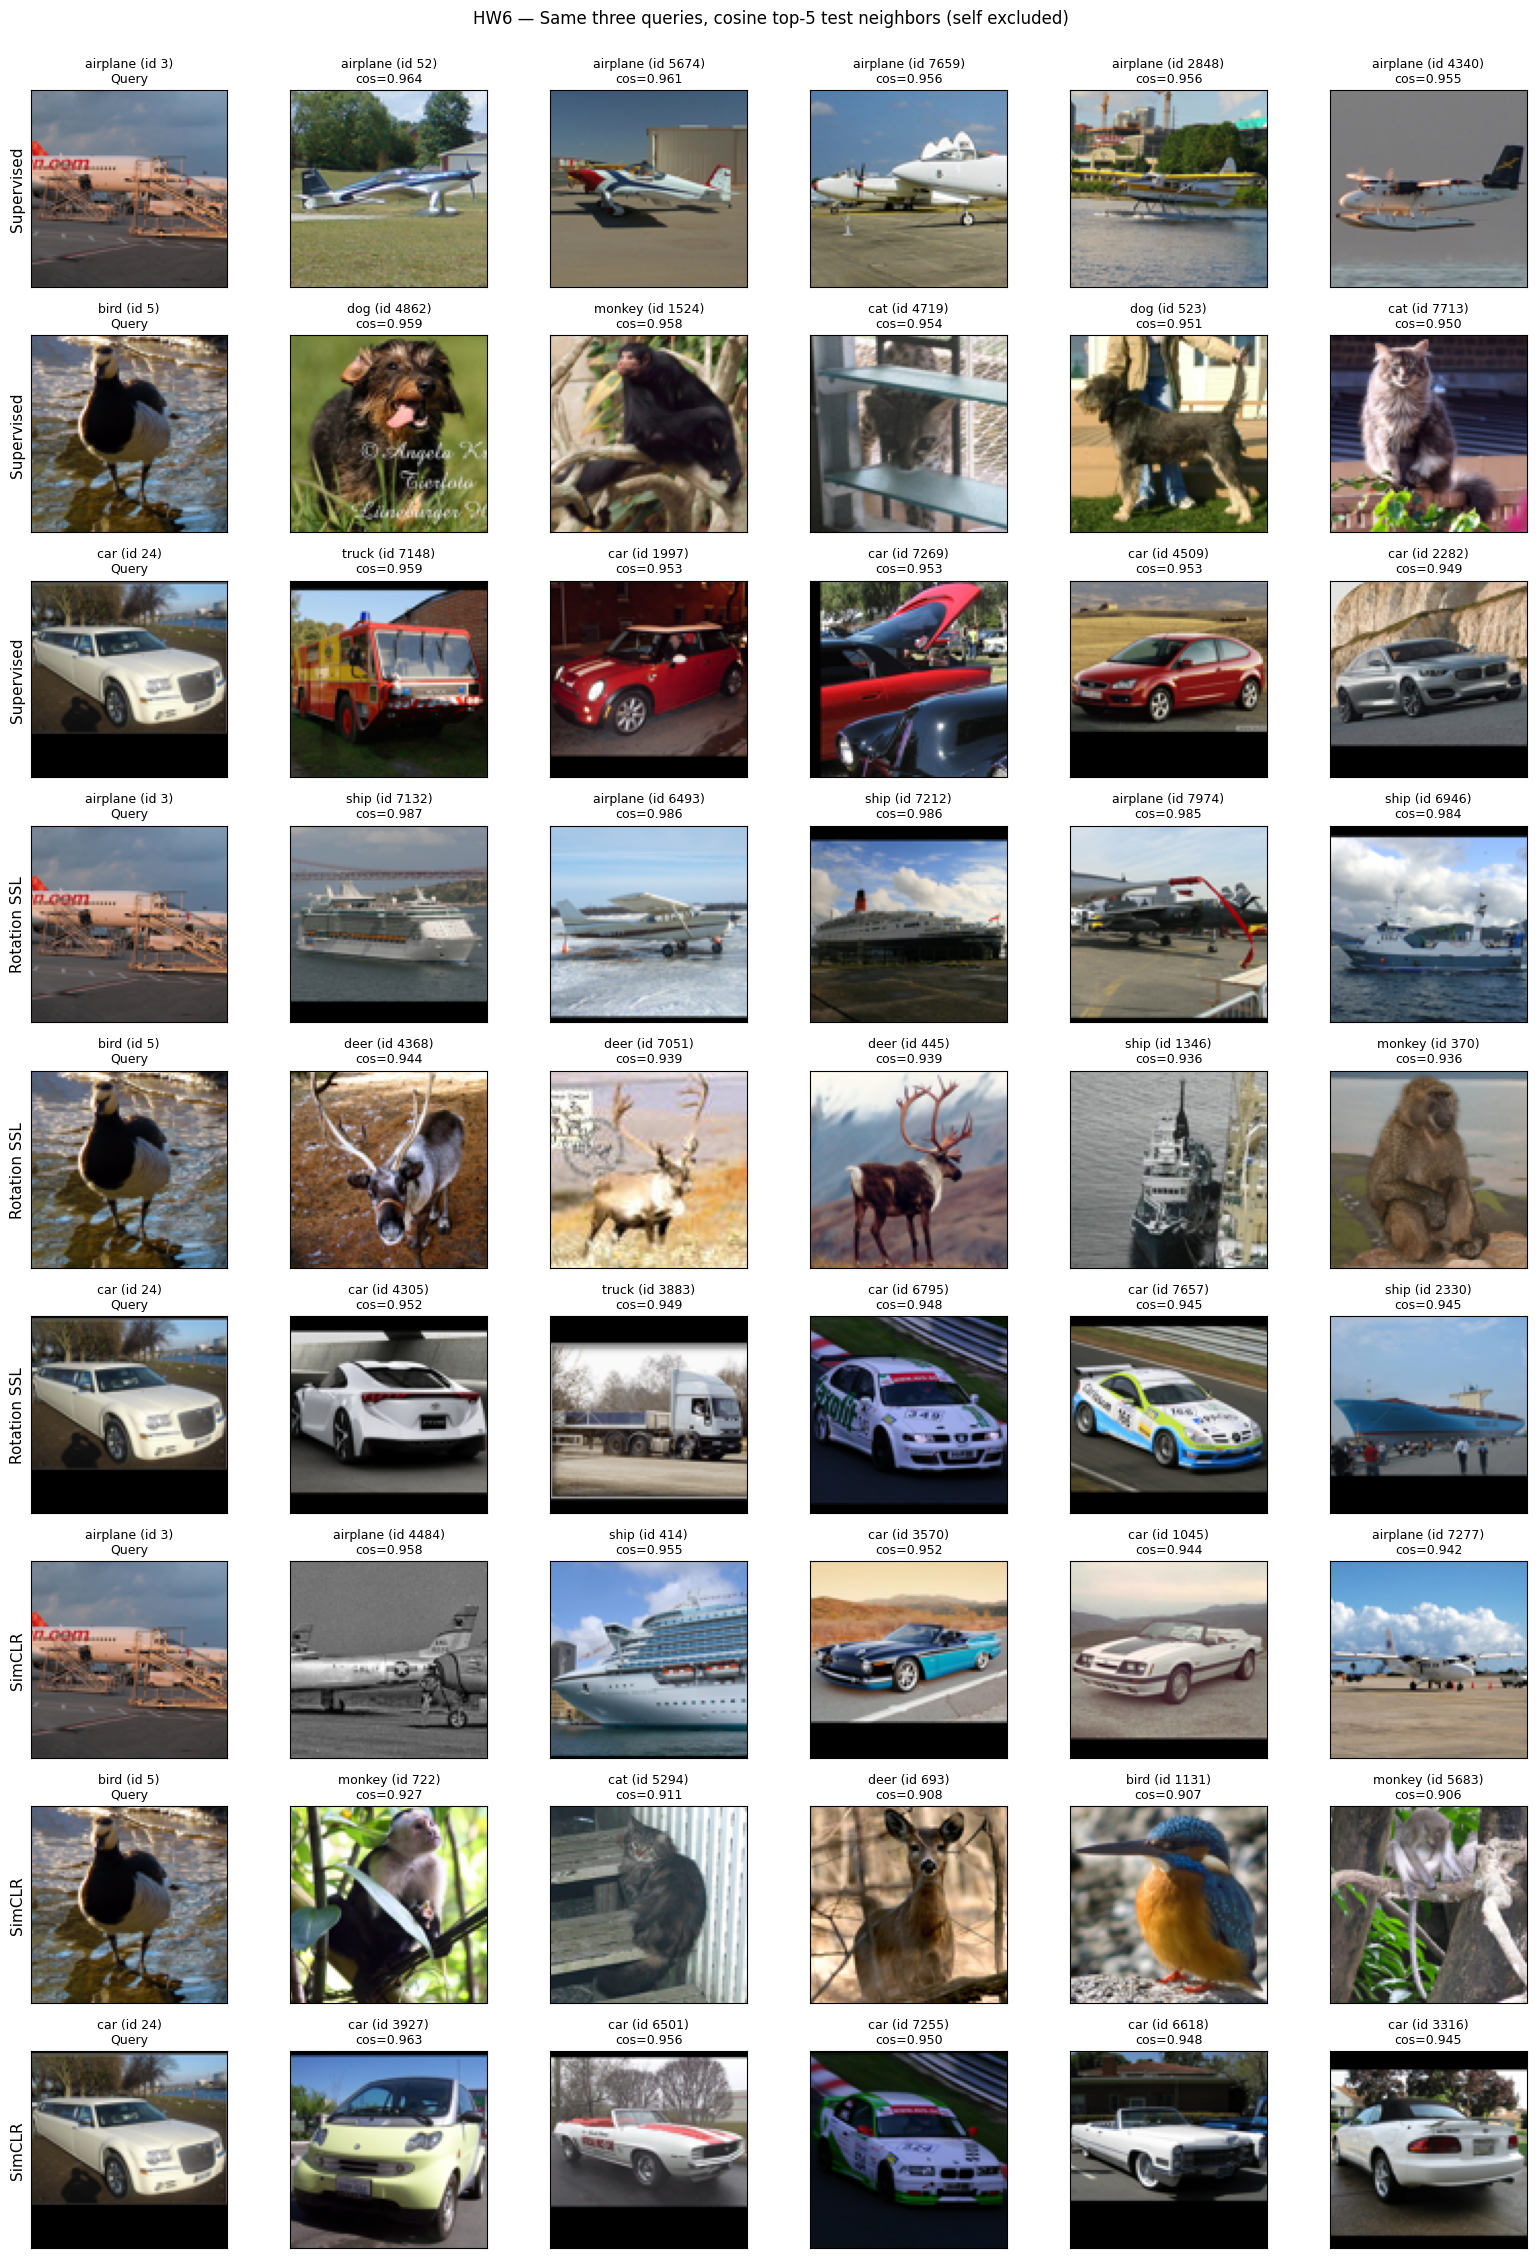

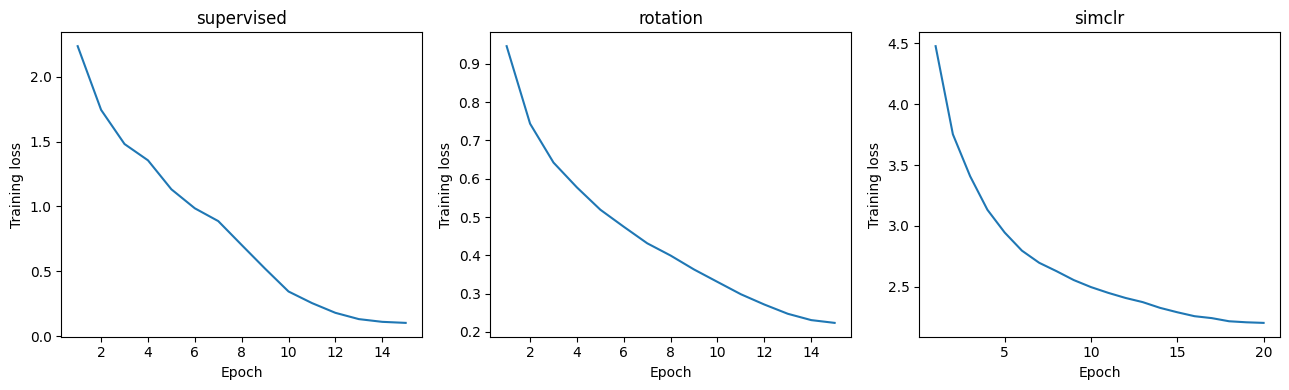

| Encoder | Test accuracy | Mean query precision@5 |
|---|---:|---:|
| Supervised | 43.60% | 60.00% |
| Rotation SSL | 46.30% | 33.33% |
| SimCLR | 51.79% | 53.33% |
Artifacts written to /content/hw6_outputs
END HW6 Part D report


In [6]:
def nearest_neighbors(features, query, k=5):
    features = F.normalize(features, dim=1)
    similarities = features[query] @ features.T
    similarities[query] = -torch.inf
    return similarities.topk(k)


def report(results, features, labels, raw_test, classes):
    query_ids = [int(torch.where(labels == c)[0][0]) for c in (0, 1, 2)]
    (OUT / 'query_indices.json').write_text(json.dumps(query_ids))
    records, observations = [], []
    fig, axes = plt.subplots(9, 6, figsize=(16, 23))
    for model_i, (name, feats) in enumerate(features.items()):
        matches = []
        torch.save(dict(embeddings=feats, labels=labels), OUT / f'{name.replace(" ", "_")}_embeddings.pt')
        for query_i, query in enumerate(query_ids):
            scores, neighbors = nearest_neighbors(feats, query)
            ids = [query] + neighbors.tolist()
            row = model_i * 3 + query_i
            same = int((labels[neighbors] == labels[query]).sum())
            matches.append(same / 5)
            retrieved = ', '.join(classes[int(labels[j])] for j in neighbors)
            observations.append(f'- {name}, query {query} ({classes[int(labels[query])]}): '
                                f'{same}/5 share the query class; retrieved {retrieved}.')
            for col, idx in enumerate(ids):
                axes[row, col].imshow(raw_test[idx][0])
                caption = f'{classes[int(labels[idx])]} (id {idx})'
                caption += '\nQuery' if col == 0 else f'\ncos={scores[col-1]:.3f}'
                axes[row, col].set_title(caption, fontsize=9)
                axes[row, col].set_xticks([])
                axes[row, col].set_yticks([])
                if col == 0:
                    axes[row, col].set_ylabel(name, fontsize=11)
            for rank, (idx, score) in enumerate(zip(neighbors.tolist(), scores.tolist()), 1):
                records.append(dict(model=name, query=query, query_class=classes[int(labels[query])],
                                    rank=rank, neighbor=idx, neighbor_class=classes[int(labels[idx])],
                                    cosine=score))
        results[name]['query_precision_at_5'] = float(np.mean(matches))
    fig.suptitle('HW6 — Same three queries, cosine top-5 test neighbors (self excluded)')
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    fig.savefig(OUT / 'nearest_neighbors.png', dpi=160)
    plt.show()
    with (OUT / 'neighbors.csv').open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=records[0].keys())
        writer.writeheader()
        writer.writerows(records)
    (OUT / 'metrics.json').write_text(json.dumps(results, indent=2))
    table = '| Encoder | Test accuracy | Mean query precision@5 |\n|---|---:|---:|\n'
    table += '\n'.join(f'| {k} | {v["test_accuracy"]*100:.2f}% | {v["query_precision_at_5"]*100:.2f}% |'
                       for k, v in results.items())
    best = max(v['test_accuracy'] for v in results.values())
    winners = [k for k, v in results.items() if abs(v['test_accuracy']-best) < 1e-9]
    text = '# Homework 6 — Measured findings\n\n' + table
    text += '\n\nHighest measured test accuracy: ' + ', '.join(winners) + f' ({best*100:.2f}%).'
    text += '\nThis identifies the winner for this single seed and training budget, not a universal ordering.\n'
    text += '\n## Interpreting performance\n\n'
    text += ('Supervised learning directly optimizes semantic labels, but only 500 examples constrain a large '
             'encoder. A strong result is consistent with objective alignment; a weak result is consistent '
             'with limited labels and overfitting. Stronger label-preserving augmentation, weight decay '
             'tuning, and a validation split within the label budget could improve it.\n\n'
             'Rotation SSL sees all 100,000 unlabeled images and can learn shape and orientation cues. '
             'Its objective can also favor horizons/backgrounds or orientation shortcuts rather than class '
             'identity; rotation prediction is ambiguous for some objects. Longer pretraining and spatial '
             'augmentation that discourages shortcuts may improve frozen semantic features.\n\n'
             'SimCLR learns invariance to cropping and appearance changes, which can support semantic '
             'retrieval. This short run uses only 20,000 images and a modest batch, so limited negatives, '
             'training time, overly destructive crops, or same-class negatives can limit accuracy. '
             'More unlabeled images, longer pretraining, larger batches when memory allows, and '
             'careful augmentation tuning could help. These are hypotheses, not causal conclusions '
             'established by this three-model experiment.\n\n'
             'The comparison controls architecture and labeled examples, but not pretraining data or '
             'compute: supervised uses no unlabeled data, rotation uses 100,000 images, and SimCLR '
             'uses 20,000. Report this when explaining the ranking.\n\n')
    text += '## What the neighbors reveal\n\n' + '\n'.join(observations)
    retrieval_best = max(results, key=lambda k: results[k]['query_precision_at_5'])
    text += (f'\n\n{retrieval_best} has the highest mean precision@5 among these three queries '
             '(ties may exist). Same-class neighbors indicate local semantic grouping; wrong-class '
             'neighbors expose regions where class structure is weaker. Three queries are illustrative, '
             'not a population estimate. Inspect nearest_neighbors.png to identify specific shared '
             'shapes, colors, poses or backgrounds; class matches alone do not establish which visual '
             'cue caused a retrieval. High cosine similarity alone does not prove semantic quality.\n')
    text += '\n![Nearest neighbors](nearest_neighbors.png)\n'
    (OUT / 'HW6_findings.md').write_text(text, encoding='utf-8')
    (OUT / 'METRICS.md').write_text('# Homework 6 metrics\n\n' + table, encoding='utf-8')
    Path('METRICS.md').write_text('# Homework 6 metrics\n\n' + table, encoding='utf-8')
    checkpoint_text = '# HW6 checkpoints\n\nTraining command: `python hw6.py` (Windows: `py -3 hw6.py`).\n\n'
    checkpoint_text += 'Equivalent: run every cell in HW6_STL10_Representation_Learning.ipynb in order.\n\n'
    checkpoint_text += 'Software/hardware and exact configuration: environment.json and config.json.\n\n'
    checkpoint_text += '\n'.join(f'- `{p.name}`: SHA256 `{hashlib.sha256(p.read_bytes()).hexdigest()}`'
                                  for p in sorted(OUT.glob('*.pt')) if 'embeddings' not in p.name)
    checkpoint_text += '\n\nUpload checkpoints to persistent storage and record accessible links before submission.\n'
    (OUT / 'CHECKPOINTS.md').write_text(checkpoint_text, encoding='utf-8')
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, stage in zip(axes, ['supervised', 'rotation', 'simclr']):
        history = json.loads((OUT / f'{stage}_history.json').read_text())
        ax.plot([h['epoch'] for h in history], [h['loss'] for h in history])
        ax.set(title=stage, xlabel='Epoch', ylabel='Training loss')
    fig.tight_layout()
    fig.savefig(OUT / 'training_losses.png', dpi=150)
    plt.show()
    print(table)
    print(f'Artifacts written to {OUT.resolve()}')


if __name__ == '__main__':
    with capture_run('Part D report'):
        report(results, test_features, labels, data['raw_test'], data['classes'])